**Tutorial Setup Awal Python Geospatial**
Modul utama yang digunakan:

1. pandas (manipulasi data tabular)
2. geopandas (data spasial/geografi)
3. folium (visualisasi peta interaktif)
4. matplotlib & seaborn (visualisasi statistik)
5. numpy (analisis numerik)
6. shapely (manipulasi geometri)

Instalasi di Windows (Command Prompt):

"pip install pandas geopandas folium matplotlib seaborn numpy shapely"

Instalasi di MacOS/Linux (Terminal):

"python3 -m pip install pandas geopandas folium matplotlib seaborn numpy shapely"


1️⃣ Import Library
Pada tahap ini, seluruh library Python yang dibutuhkan untuk analisis data spasial dan statistik diimpor.

1. pandas (import pandas as pd): Manipulasi data tabular.
2. geopandas (import geopandas as gpd): Membaca dan mengolah data spasial (GeoJSON).
3. folium (import folium): Membuat peta interaktif berbasis leaflet.
4. matplotlib.pyplot (import matplotlib.pyplot as plt): Visualisasi grafik.
5. seaborn (import seaborn as sns): Visualisasi statistik.
6. numpy (import numpy as np): Operasi numerik.
7. shapely.geometry (from shapely.geometry import Polygon, Point): Membuat dan memanipulasi objek geometri polygon/titik.

In [61]:
# Jalankan di terminal jika belum install
import pandas as pd
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import Polygon, Point


2️⃣ Load Data GeoJSON
Data spasial potensi hidrokarbon dibaca dari file GeoJSON menggunakan geopandas.
GeoJSON berisi informasi polygon area, beserta atribut seperti nama wilayah, potensi hidrokarbon, kedalaman, jenis batuan, dan parameter reservoir lainnya.

1. gpd.read_file(path): Membaca file GeoJSON menjadi GeoDataFrame.
2. print(gdf_geojson.head()): Menampilkan 5 baris pertama data.

In [62]:
#path file
geojson_path = r"D:\Users\kkb24057\Downloads\MAPID WebGIS Development Bootcamp Batch 2\MAPID_WEBGIS_BOOTCAMP_TRIAL\labs\data_dummy_hidrokarbon.geojson"


In [63]:
# Load data
gdf_geojson = gpd.read_file(geojson_path)

print(gdf_geojson.head())

     wilayah  potensi_hidrokarbon  kedalaman jenis_batuan  porositas  \
0    Cirebon                  120       2500    Sandstone         18   
1     Bekasi                  200       3200    Limestone         22   
2   Karawang                  150       2800        Shale         15   
3     Subang                   80       2100    Sandstone         20   
4  Indramayu                  170       3000        Shale         17   

   permeabilitas kecamatan                                           geometry  
0            120    Kec. A  POLYGON ((108.5 -6.7, 108.6 -6.7, 108.6 -6.6, ...  
1            210    Kec. B  POLYGON ((107 -6.3, 107.1 -6.3, 107.1 -6.2, 10...  
2             90    Kec. C  POLYGON ((107.3 -6.2, 107.4 -6.2, 107.4 -6.1, ...  
3            160    Kec. D  POLYGON ((107.7 -6.5, 107.8 -6.5, 107.8 -6.4, ...  
4            130    Kec. E  POLYGON ((108 -6.4, 108.1 -6.4, 108.1 -6.3, 10...  


3️⃣ Hitung Centroid Polygon & Buat DataFrame Analisis
Setiap polygon area dihitung titik tengahnya (centroid) secara otomatis.
Latitude dan longitude centroid ditambahkan ke DataFrame, sehingga setiap wilayah memiliki representasi titik pusat.

1. gdf_geojson.geometry.centroid: Menghitung titik tengah (centroid) dari polygon.
2. .x, .y: Mengambil longitude dan latitude dari centroid.
3. .copy(): Membuat salinan DataFrame.

In [64]:
# Hitung centroid dari geometry polygon
gdf_geojson['centroid'] = gdf_geojson.geometry.centroid
gdf_geojson['longitude'] = gdf_geojson['centroid'].x
gdf_geojson['latitude'] = gdf_geojson['centroid'].y

# DataFrame dengan semua kolom + centroid
df_hidrokarbon = gdf_geojson.copy()

print(df_hidrokarbon)


      wilayah  potensi_hidrokarbon  kedalaman jenis_batuan  porositas  \
0     Cirebon                  120       2500    Sandstone         18   
1      Bekasi                  200       3200    Limestone         22   
2    Karawang                  150       2800        Shale         15   
3      Subang                   80       2100    Sandstone         20   
4   Indramayu                  170       3000        Shale         17   
5  Purwakarta                  110       2600    Limestone         19   
6  Majalengka                   95       2400    Sandstone         16   
7    Sumedang                  130       2700        Shale         21   
8     Bandung                   60       1800    Limestone         14   
9       Garut                   75       2200    Sandstone         18   

   permeabilitas kecamatan                                           geometry  \
0            120    Kec. A  POLYGON ((108.5 -6.7, 108.6 -6.7, 108.6 -6.6, ...   
1            210    Kec. B  POLYGO

D:\Users\kkb24057\AppData\Local\Temp\ipykernel_12260\1506890904.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_geojson['centroid'] = gdf_geojson.geometry.centroid


4️⃣ Statistik Deskriptif
Statistik deskriptif digunakan untuk memahami karakteristik dasar data, seperti rata-rata, standar deviasi, nilai minimum, dan maksimum dari setiap parameter numerik.

1. df_hidrokarbon.describe(): Statistik deskriptif (mean, std, min, max, dll).

In [65]:
# Statistik deskriptif seluruh parameter numerik
print("Statistik Deskriptif:")
print(df_hidrokarbon.describe())

Statistik Deskriptif:
       potensi_hidrokarbon    kedalaman  porositas  permeabilitas   longitude  \
count            10.000000    10.000000  10.000000      10.000000   10.000000   
mean            119.000000  2530.000000  18.000000     125.500000  107.740000   
std              44.522154   424.394994   2.581989      37.892391    0.477144   
min              60.000000  1800.000000  14.000000      80.000000  107.050000   
25%              83.750000  2250.000000  16.250000     102.500000  107.400000   
50%             115.000000  2550.000000  18.000000     117.500000  107.700000   
75%             145.000000  2775.000000  19.750000     137.500000  108.000000   
max             200.000000  3200.000000  22.000000     210.000000  108.550000   

        latitude  
count  10.000000  
mean   -6.560000  
std     0.268535  
min    -6.950000  
25%    -6.750000  
50%    -6.550000  
75%    -6.375000  
max    -6.150000  


5️⃣ Distribusi Potensi Hidrokarbon (Histogram)
Visualisasi histogram digunakan untuk melihat sebaran nilai potensi hidrokarbon di seluruh wilayah.

1. plt.figure(): Membuat canvas plot.
2. sns.histplot(): Membuat histogram distribusi data.
3. plt.title(), plt.xlabel(), plt.ylabel(): Judul dan label sumbu.
4. plt.tight_layout(): Merapikan layout.
5. plt.show(): Menampilkan plot.

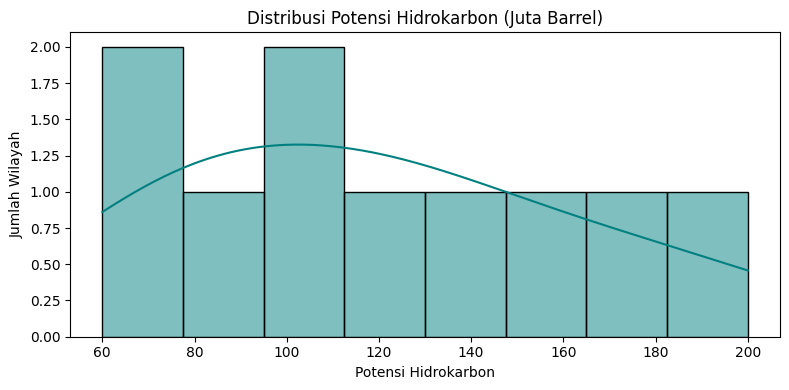

In [66]:
plt.figure(figsize=(8,4))
sns.histplot(df_hidrokarbon['potensi_hidrokarbon'], bins=8, kde=True, color='teal')
plt.title('Distribusi Potensi Hidrokarbon (Juta Barrel)')
plt.xlabel('Potensi Hidrokarbon')
plt.ylabel('Jumlah Wilayah')
plt.tight_layout()
plt.show()

6️⃣ Boxplot Potensi Hidrokarbon per Jenis Batuan
Boxplot membandingkan sebaran potensi hidrokarbon berdasarkan jenis batuan reservoir.

1. sns.boxplot(): Membuat boxplot per kategori.
2. plt.title(), plt.xlabel(), plt.ylabel(), plt.tight_layout(), plt.show(): Visualisasi.

D:\Users\kkb24057\AppData\Local\Temp\ipykernel_12260\2382431152.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='jenis_batuan', y='potensi_hidrokarbon', data=df_hidrokarbon, palette='Set2')


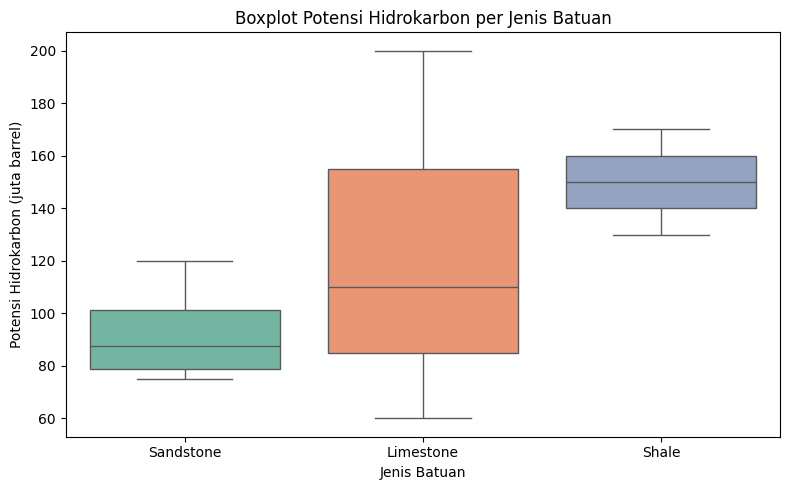

In [67]:
plt.figure(figsize=(8,5))
sns.boxplot(x='jenis_batuan', y='potensi_hidrokarbon', data=df_hidrokarbon, palette='Set2')
plt.title('Boxplot Potensi Hidrokarbon per Jenis Batuan')
plt.xlabel('Jenis Batuan')
plt.ylabel('Potensi Hidrokarbon (juta barrel)')
plt.tight_layout()
plt.show()


7️⃣ Scatter Plot Potensi vs Kedalaman, Porositas, Permeabilitas
Scatter plot digunakan untuk menganalisis hubungan antara kedalaman, potensi hidrokarbon, dan parameter reservoir lainnya.

1. sns.scatterplot(): Membuat scatter plot dengan warna dan ukuran berbeda.
2. plt.title(), plt.xlabel(), plt.ylabel(), plt.tight_layout(), plt.show(): Visualisasi.

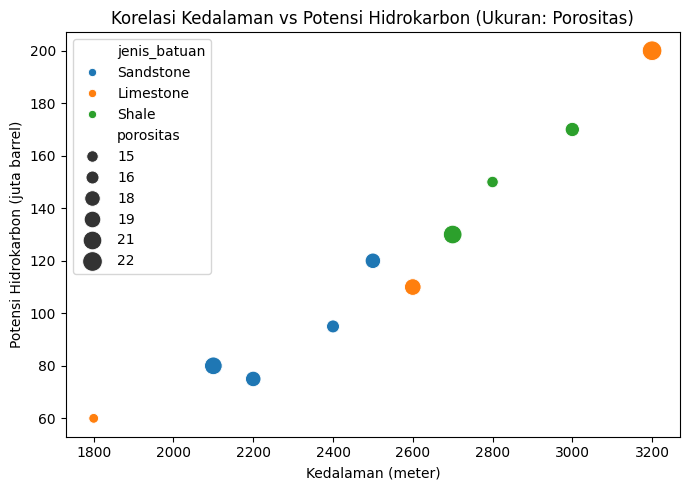

In [68]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x='kedalaman', y='potensi_hidrokarbon', 
    data=df_hidrokarbon, hue='jenis_batuan', size='porositas', sizes=(50, 200), palette='tab10'
)
plt.title('Korelasi Kedalaman vs Potensi Hidrokarbon (Ukuran: Porositas)')
plt.xlabel('Kedalaman (meter)')
plt.ylabel('Potensi Hidrokarbon (juta barrel)')
plt.tight_layout()
plt.show()


8️⃣ Heatmap Korelasi Antar Parameter Reservoir
Heatmap korelasi menampilkan hubungan antar parameter numerik seperti potensi, kedalaman, porositas, dan permeabilitas.

1. df_hidrokarbon.corr(): Menghitung matriks korelasi antar kolom numerik.
2. sns.heatmap(): Membuat heatmap dari matriks korelasi.
3. plt.title(), plt.tight_layout(), plt.show(): Visualisasi.

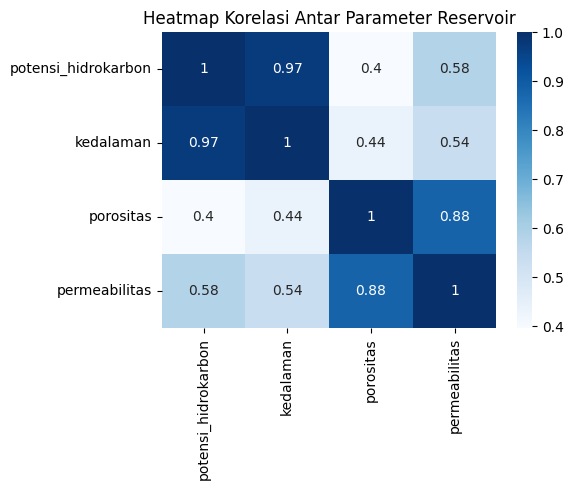

In [69]:
corr_matrix = df_hidrokarbon[['potensi_hidrokarbon', 'kedalaman', 'porositas', 'permeabilitas']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues')
plt.title('Heatmap Korelasi Antar Parameter Reservoir')
plt.tight_layout()
plt.show()


9️⃣ Peta Statis Potensi Hidrokarbon Jawa Barat
Peta statis menampilkan area potensi hidrokarbon di Jawa Barat dengan warna yang merepresentasikan besaran potensi.

1. df_hidrokarbon.plot(): Plot peta spasial dari GeoDataFrame.
2. ax.annotate(): Menambahkan label nama wilayah di peta.
3. plt.title(), plt.axis('off'), plt.show(): Visualisasi.

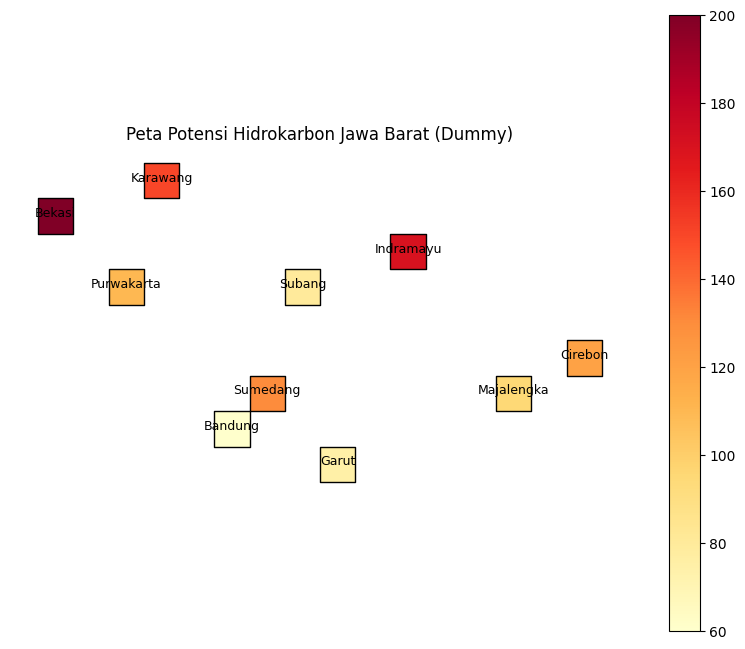

In [70]:
fig, ax = plt.subplots(figsize=(10,8))
df_hidrokarbon.plot(column='potensi_hidrokarbon', ax=ax, legend=True, cmap='YlOrRd', edgecolor='black')
for idx, row in df_hidrokarbon.iterrows():
    ax.annotate(
        text=row['wilayah'],
        xy=(row['longitude'], row['latitude']),
        ha='center',
        fontsize=9,
        color='black'
    )
plt.title('Peta Potensi Hidrokarbon Jawa Barat (Dummy)')
plt.axis('off')
plt.show()


🔟 Cluster Potensi Hidrokarbon
Wilayah dikelompokkan ke dalam cluster berdasarkan nilai potensi hidrokarbon: tinggi, sedang, dan rendah.

1. Fungsi custom cluster_potensi: Mengelompokkan data berdasarkan nilai potensi.
2. df_hidrokarbon.apply(): Menerapkan fungsi ke kolom DataFrame.

In [71]:
def cluster_potensi(val):
    if val > 150:
        return 'Tinggi'
    elif val >= 100:
        return 'Sedang'
    else:
        return 'Rendah'

df_hidrokarbon['cluster_potensi'] = df_hidrokarbon['potensi_hidrokarbon'].apply(cluster_potensi)
print(df_hidrokarbon[['wilayah', 'potensi_hidrokarbon', 'cluster_potensi']])


      wilayah  potensi_hidrokarbon cluster_potensi
0     Cirebon                  120          Sedang
1      Bekasi                  200          Tinggi
2    Karawang                  150          Sedang
3      Subang                   80          Rendah
4   Indramayu                  170          Tinggi
5  Purwakarta                  110          Sedang
6  Majalengka                   95          Rendah
7    Sumedang                  130          Sedang
8     Bandung                   60          Rendah
9       Garut                   75          Rendah


1️⃣1️⃣ Visualisasi Cluster Potensi
Bar chart jumlah wilayah per cluster potensi hidrokarbon divisualisasikan untuk mengetahui proporsi masing-masing kategori.

1. sns.countplot(): Membuat bar chart jumlah kategori cluster.
2. plt.title(), plt.xlabel(), plt.ylabel(), plt.tight_layout(), plt.show(): Visualisasi.

D:\Users\kkb24057\AppData\Local\Temp\ipykernel_12260\1681094022.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='cluster_potensi', data=df_hidrokarbon, palette='viridis')


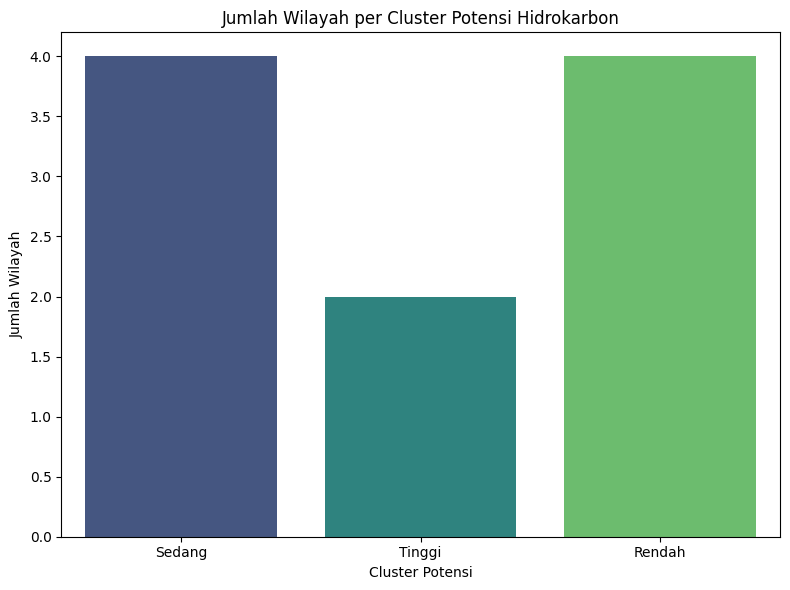

In [72]:
plt.figure(figsize=(8,6))
sns.countplot(x='cluster_potensi', data=df_hidrokarbon, palette='viridis')
plt.title('Jumlah Wilayah per Cluster Potensi Hidrokarbon')
plt.xlabel('Cluster Potensi')
plt.ylabel('Jumlah Wilayah')
plt.tight_layout()
plt.show()


1️⃣2️⃣ Statistik Parameter Reservoir per Cluster
Rata-rata parameter reservoir (porositas, permeabilitas, kedalaman) dihitung untuk setiap cluster potensi.

1. df_hidrokarbon.groupby(): Mengelompokkan data berdasarkan cluster.
2. .mean(): Menghitung rata-rata tiap kelompok.

In [73]:
print("Statistik parameter reservoir per cluster potensi:")
print(df_hidrokarbon.groupby('cluster_potensi')[['porositas', 'permeabilitas', 'kedalaman']].mean())


Statistik parameter reservoir per cluster potensi:
                 porositas  permeabilitas  kedalaman
cluster_potensi                                     
Rendah               17.00         112.50     2125.0
Sedang               18.25         116.25     2650.0
Tinggi               19.50         170.00     3100.0


1️⃣3️⃣ Identifikasi Area Prospek (Multi-Parameter)
Wilayah dengan potensi, porositas, dan permeabilitas tinggi diidentifikasi sebagai area prospek utama untuk eksplorasi hidrokarbon.

1. Filtering DataFrame dengan beberapa kondisi (&): Seleksi multi-parameter.
2. Menampilkan subset kolom: Hasil seleksi.

In [74]:
prospek = df_hidrokarbon[
    (df_hidrokarbon['potensi_hidrokarbon'] > 120) &
    (df_hidrokarbon['porositas'] > 17) &
    (df_hidrokarbon['permeabilitas'] > 120)
]
print("Area prospek hidrokarbon (multi-parameter):")
print(prospek[['wilayah', 'potensi_hidrokarbon', 'porositas', 'permeabilitas']])


Area prospek hidrokarbon (multi-parameter):
    wilayah  potensi_hidrokarbon  porositas  permeabilitas
1    Bekasi                  200         22            210
7  Sumedang                  130         21            140


1️⃣4️⃣ Analisis Outlier Potensi Hidrokarbon
Outlier dideteksi menggunakan metode IQR (Interquartile Range) untuk menemukan wilayah dengan potensi hidrokarbon yang sangat tinggi atau rendah.

1. df_hidrokarbon.quantile(): Menghitung kuartil data.
2. Filtering DataFrame untuk outlier (IQR): Seleksi outlier.
3. Menampilkan subset kolom: Hasil seleksi.

In [75]:
q1 = df_hidrokarbon['potensi_hidrokarbon'].quantile(0.25)
q3 = df_hidrokarbon['potensi_hidrokarbon'].quantile(0.75)
iqr = q3 - q1
outliers = df_hidrokarbon[
    (df_hidrokarbon['potensi_hidrokarbon'] < (q1 - 1.5*iqr)) |
    (df_hidrokarbon['potensi_hidrokarbon'] > (q3 + 1.5*iqr))
]
print("Wilayah yang terdeteksi sebagai outlier potensi hidrokarbon:")
print(outliers[['wilayah', 'potensi_hidrokarbon']])


Wilayah yang terdeteksi sebagai outlier potensi hidrokarbon:
Empty DataFrame
Columns: [wilayah, potensi_hidrokarbon]
Index: []


1️⃣5️⃣ Analisis Hubungan Porositas dan Permeabilitas
Scatter plot hubungan porositas dan permeabilitas per cluster potensi digunakan untuk memahami karakteristik fisik reservoir.

1. sns.scatterplot(): Scatter plot hubungan dua parameter.
2. plt.title(), plt.xlabel(), plt.ylabel(), plt.tight_layout(), plt.show(): Visualisasi.

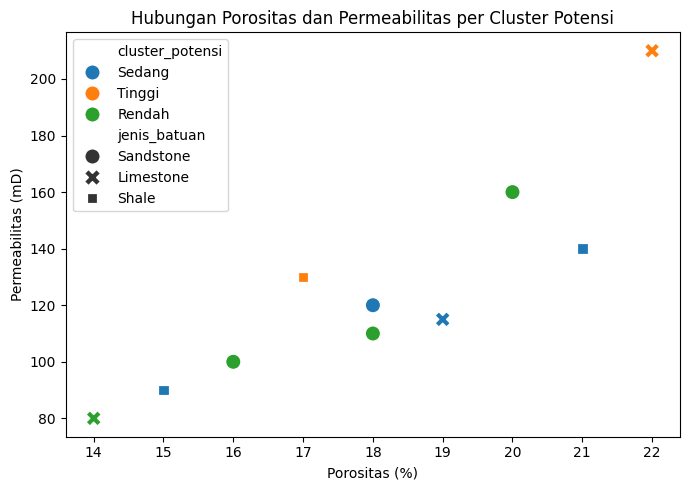

In [76]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x='porositas', y='permeabilitas', 
    data=df_hidrokarbon, hue='cluster_potensi', style='jenis_batuan', s=120
)
plt.title('Hubungan Porositas dan Permeabilitas per Cluster Potensi')
plt.xlabel('Porositas (%)')
plt.ylabel('Permeabilitas (mD)')
plt.tight_layout()
plt.show()


1️⃣6️⃣ Rata-rata Potensi per Jenis Batuan
Rata-rata potensi hidrokarbon dihitung untuk setiap jenis batuan.

1. df_hidrokarbon.groupby(): Mengelompokkan data.
2. .mean(): Rata-rata tiap kelompok.
3. .sort_values(): Urutkan hasil.

In [77]:
mean_potensi_batuan = df_hidrokarbon.groupby('jenis_batuan')['potensi_hidrokarbon'].mean().sort_values(ascending=False)
print("Rata-rata potensi hidrokarbon per jenis batuan:")
print(mean_potensi_batuan)


Rata-rata potensi hidrokarbon per jenis batuan:
jenis_batuan
Shale        150.000000
Limestone    123.333333
Sandstone     92.500000
Name: potensi_hidrokarbon, dtype: float64


1️⃣7️⃣ Rata-rata Potensi per Kecamatan
Rata-rata potensi hidrokarbon dihitung untuk setiap kecamatan.

1. df_hidrokarbon.groupby(): Mengelompokkan data.
2. .mean(): Rata-rata tiap kelompok.

In [78]:
mean_potensi_kecamatan = df_hidrokarbon.groupby('kecamatan')['potensi_hidrokarbon'].mean()
print("Rata-rata potensi hidrokarbon per kecamatan:")
print(mean_potensi_kecamatan)


Rata-rata potensi hidrokarbon per kecamatan:
kecamatan
Kec. A    120.0
Kec. B    200.0
Kec. C    150.0
Kec. D     80.0
Kec. E    170.0
Kec. F    110.0
Kec. G     95.0
Kec. H    130.0
Kec. I     60.0
Kec. J     75.0
Name: potensi_hidrokarbon, dtype: float64


1️⃣8️⃣ Kesimpulan ESDA
Kesimpulan ESDA dihasilkan secara otomatis dari hasil analisis statistik dan spasial.

1. .idxmax(), .max(): Cari nilai maksimum dan wilayahnya.
2. .value_counts(): Hitung jumlah tiap kategori cluster.
3. .tolist(), .join(): Format list jadi string.
4. .corr(): Korelasi antar parameter.
5. Print string kesimpulan otomatis: Output insight analisis.


In [79]:
# Wilayah dengan potensi hidrokarbon tertinggi
wilayah_max = df_hidrokarbon.loc[df_hidrokarbon['potensi_hidrokarbon'].idxmax(), 'wilayah']
potensi_max = df_hidrokarbon['potensi_hidrokarbon'].max()

# Cluster potensi
cluster_counts = df_hidrokarbon['cluster_potensi'].value_counts()
cluster_str = ', '.join([f"{v} wilayah {k.lower()}" for k, v in cluster_counts.items()])

# Area prospek multi-parameter
prospek_wilayah = prospek['wilayah'].tolist()
prospek_str = ', '.join(prospek_wilayah) if prospek_wilayah else "Tidak ada"

# Korelasi porositas dan permeabilitas
corr_por_perm = df_hidrokarbon['porositas'].corr(df_hidrokarbon['permeabilitas'])

# Outlier wilayah
outlier_wilayah = outliers['wilayah'].tolist()
outlier_str = ', '.join(outlier_wilayah) if outlier_wilayah else "Tidak ada"

print(f"""
Kesimpulan ESDA:
- Wilayah dengan potensi hidrokarbon tertinggi: {wilayah_max} ({potensi_max} juta barrel).
- Cluster potensi: {cluster_str}.
- Area prospek (multi-parameter): {prospek_str}.
- Korelasi porositas dan permeabilitas: {corr_por_perm:.2f}.
- Outlier terdeteksi di wilayah: {outlier_str}.
- Analisis spasial dan statistik membantu identifikasi area prioritas eksplorasi.
""")



Kesimpulan ESDA:
- Wilayah dengan potensi hidrokarbon tertinggi: Bekasi (200 juta barrel).
- Cluster potensi: 4 wilayah sedang, 4 wilayah rendah, 2 wilayah tinggi.
- Area prospek (multi-parameter): Bekasi, Sumedang.
- Korelasi porositas dan permeabilitas: 0.88.
- Outlier terdeteksi di wilayah: Tidak ada.
- Analisis spasial dan statistik membantu identifikasi area prioritas eksplorasi.



1️⃣9️⃣ WebGIS Mini Folium
Peta interaktif WebGIS dibuat menggunakan folium, menampilkan polygon wilayah, marker centroid, dan popup info statistik.

1. folium.Map(): Membuat peta interaktif.
2. folium.GeoJson(): Layer polygon wilayah.
3. folium.Marker(): Marker centroid tiap wilayah.
4. folium.Popup(), folium.Html(): Popup info/summary.
5. .save(): Simpan peta ke file HTML.

In [80]:
# Buat string kesimpulan otomatis dari hasil analisis
wilayah_max = df_hidrokarbon.loc[df_hidrokarbon['potensi_hidrokarbon'].idxmax(), 'wilayah']
potensi_max = df_hidrokarbon['potensi_hidrokarbon'].max()
cluster_counts = df_hidrokarbon['cluster_potensi'].value_counts()
cluster_str = ', '.join([f"{v} wilayah {k.lower()}" for k, v in cluster_counts.items()])
prospek_wilayah = prospek['wilayah'].tolist()
prospek_str = ', '.join(prospek_wilayah) if prospek_wilayah else "Tidak ada"
corr_por_perm = df_hidrokarbon['porositas'].corr(df_hidrokarbon['permeabilitas'])
outlier_wilayah = outliers['wilayah'].tolist()
outlier_str = ', '.join(outlier_wilayah) if outlier_wilayah else "Tidak ada"

kesimpulan_html = f"""
<b>Kesimpulan ESDA:</b><br>
- Wilayah dengan potensi hidrokarbon tertinggi: <b>{wilayah_max}</b> ({potensi_max} juta barrel).<br>
- Cluster potensi: {cluster_str}.<br>
- Area prospek (multi-parameter): {prospek_str}.<br>
- Korelasi porositas dan permeabilitas: {corr_por_perm:.2f}.<br>
- Outlier terdeteksi di wilayah: {outlier_str}.<br>
- Analisis spasial dan statistik membantu identifikasi area prioritas eksplorasi.
"""

# Drop kolom centroid (Point) sebelum visualisasi
df_geojson_only = df_hidrokarbon.drop(columns=['centroid'])

# Center peta dari rata-rata centroid
center = [df_geojson_only['latitude'].mean(), df_geojson_only['longitude'].mean()]
m = folium.Map(location=center, zoom_start=8, tiles='OpenStreetMap')

# Tambahkan polygon wilayah
folium.GeoJson(
    df_geojson_only,
    style_function=lambda feature: {
        'fillColor': '#3186cc',
        'color': 'black',
        'weight': 2,
        'fillOpacity': 0.5,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['wilayah', 'potensi_hidrokarbon', 'kedalaman', 'jenis_batuan', 'porositas', 'permeabilitas', 'kecamatan'],
        aliases=['Wilayah:', 'Potensi (juta barrel):', 'Kedalaman (m):', 'Jenis Batuan:', 'Porositas (%):', 'Permeabilitas (mD):', 'Kecamatan:'],
        localize=True
    )
).add_to(m)

# Tambahkan marker centroid tiap wilayah
for idx, row in df_geojson_only.iterrows():
    folium.Marker(
        location=[row['latitude'], row['longitude']],
        popup=f"{row['wilayah']}<br>Potensi: {row['potensi_hidrokarbon']} juta barrel<br>Kedalaman: {row['kedalaman']} m",
        icon=folium.Icon(color='red', icon='info-sign')
    ).add_to(m)

# Tambahkan panel kesimpulan ESDA di peta (pakai folium.Html dan folium.Popup)
from folium import Html, Popup, Marker

html = Html(kesimpulan_html, script=True)
popup = Popup(html, max_width=450)
Marker(location=center, popup=popup, icon=folium.Icon(color='green', icon='info-sign')).add_to(m)

# Simpan ke file HTML
m.save('webgis_mini_hidrokarbon2.html')
print("Peta interaktif dengan kesimpulan ESDA berhasil disimpan sebagai 'webgis_mini_hidrokarbon2.html'. Silakan buka file ini di browser.")


Peta interaktif dengan kesimpulan ESDA berhasil disimpan sebagai 'webgis_mini_hidrokarbon2.html'. Silakan buka file ini di browser.
